In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.cluster import KMeans

df = pd.read_csv('penguins.csv')

In [98]:
print(df.shape, df.columns)

(344, 9) Index(['Unnamed: 0', 'species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')


In [99]:
print(df.select_dtypes(include='number').columns)
n = len(df['species'].value_counts())

Index(['Unnamed: 0', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'year'],
      dtype='str')


In [100]:
x = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g']]

In [101]:
x = x.fillna(x.mean())

In [102]:
mean = np.mean(x, axis = 0)
std = np.std(x, axis = 0)

x_scaled = (x- mean)/std

In [103]:
Kmeans = KMeans(n_clusters=n, random_state=23, n_init=22)

In [104]:
df['cluster'] = Kmeans.fit_predict(x_scaled)

In [105]:
print(pd.crosstab(df["species"], df["cluster"]))

cluster      0    1   2
species                
Adelie     127    0  25
Chinstrap    5    0  63
Gentoo       0  123   1


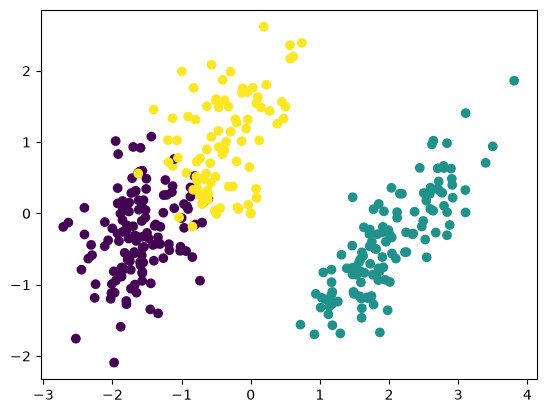

In [106]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)

X_pca = pca.fit_transform(x_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"]
)


plt.show()